# Project 2 -- Oscar (Tzu Yang) Huang

**TA Help:** N/A

**Collaboration:** My Friend in Data Mine, Vedant Mohan

- We did not help each other on the task itself, but we did get some different results in terms of difference in the Gen AI code, so we discussed a bit about how sometimes we got different library used by models due to different wording and other nuanced differences 

**Internet Resources:** Python Docs, Hubspot, reddit, matplotlib docs

- https://docs.python.org/3/library/csv.html#csv.reader: I wanted to know the parameters and use of the csv.reader function
- https://docs.python.org/3/library/functions.html: I wanted to know the parameters, use, and implementation of the "open" function
- https://blog.hubspot.com/website/what-is-utf-8: I wanted to clarify why UTF-8 was used in the open function and some misconceptions I had before this.
- https://www.reddit.com/r/learnpython/comments/14b5vww/how_does_if_name_main_work_ive_tried_to_look_at/: Easy and approachable explanation of what the if __name__ == "__main__" does
- https://realpython.com/if-name-main-python/: I wanted to further my understanding of the line above, so I dug a bit into the real python website to find more about what it does
- https://www.reddit.com/r/learnpython/comments/eb57p0/what_is_the_point_of_name_main_in_python_programs/: I wanted to learn more about the actual application of the line of code
- https://docs.python.org/3/library/sys.html: Wanted to learn a little about why Claude implemented the sys library
- https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.tight_layout.html: Wanted to know why tight_layout is used
- https://www.w3schools.com/python/ref_func_zip.asp: Wanted to know why Claude used the zip function and how it differed from ChatGPT's approach

**ChatGPT, Gemini, Claude, etc:** ChatGPT, Claude

- Used for all the questions in the project, but made sure to add my own documentation and explanation based on online documentation and other resources
- All prompts that are fed to the models are specified below each question
- No additional Gen AI is used, besides for the specified tasks and instructions

## Question 1

In [2]:
# ChatGPT generated code

import csv # Importing CSV library - this is used to read, write, and analyze csv files 

file_path = "/anvil/projects/tdm/data/consumer_complaints/complaints.csv" # Defining the file path so program knows where to access file
expected_records = 17_433_612 # Defining expected records to be compared to the actual file
record_count = 0 # Initializing a counter that will be used to compare with expected_records


# This is the open function in python, which takes in the parameters of file as the first, followed by some additional info. "r" 
# specifies the mode in which python should address the csv file, which is read. Encoding = "utf-8" specifies the decoding type
# that should be used, specifying to python how it should translate the file's binary data into readable text. "newline = " is the 
# most important one here which specifies to python how it should parse newline character.

with open(file_path, "r", encoding="utf-8", newline="") as f:
    reader = csv.reader(f) # Returns a reader object (defined as "reader") that will process lines from the csv file
    header = next(reader) # Specifies that first row of the CSV is the header

    for row in reader:
        record_count +=1
        # Loops through all the rows in the file by using the reader object, incrementing by 1 each time

print(f"Header fields: {len(header)}") 
print(f"Complaint records: {record_count}")
# This is the output method we learnt in CS180 which basically allows output to be a variable without needing to tediously
# use many add signs to string together a statement

# Checks if the record count matches the expected records 
if record_count == expected_records:
    print("✓ Record count verified.")
else:
    print(
        f"✗ Record count mismatch: "
        f"expected {expected_records:,}, got {record_count:,}"
    )

Header fields: 16
Complaint records: 17433612
✓ Record count verified.


In [3]:
# Claude generated code

import csv # Importing the CSV library - this is used to read, write, and analyze csv files 
import sys # Importing the SYS library - this is used for preventing line reading issue

EXPECTED_RECORDS = 17_433_612 # Defining expected records to be compared to the actual file
FILE_PATH = "/anvil/projects/tdm/data/consumer_complaints/complaints.csv" # Defining the file path so program knows where to access file

csv.field_size_limit(sys.maxsize) 
# (AI-explained and supported answer then worded myself) This is actually not necessary for the program, but it essentially 
# expands the csv module's built-in cap on how many characters a single field can contain before it raises an error

# Creates a counts_record function with file_path as the parameter inputted into the function
def count_records(file_path):
    with open(file_path, mode="r", newline="", encoding="utf-8") as f: 
        # The same concept as mentioned above in the ChatGPT given output
        reader = csv.reader(f) # Returns a reader object (defined as "reader") that will process lines from the csv file
        header = next(reader)  # This takes the first row as the header row as read from the reader object
        count = 0 # Initializing count variable for comparison
        for row in reader: # Looping through number of rows in reader object/csv file
            count += 1 # Incrementing count by 1 each time
    return count, header # Return count of the rows and header of the csv file

if __name__ == "__main__": # This specifies that this only runs if script is ran directly, not as an import
    record_count, header = count_records(FILE_PATH) # Calls the function and defines record_count and header of the csv file
    # print(f"Header: {header}") - I commented this, because it isn't necessary, but it outputs the header row's label
    print(f"Record count: {record_count:,}") # Outputs the total (actual) number of records/rows in the CSV file
    print(f"Expected:     {EXPECTED_RECORDS:,}") # Outputs the expected number of records/rows in the CSV file
    if record_count == EXPECTED_RECORDS: # Compares actual vs expected rows
        print("✅ Record count matches expected value.") # Correct message if matching
    else:
        diff = record_count - EXPECTED_RECORDS # Calculates the difference
        print(f"❌ Mismatch: {diff:+,} records different from expected.") # Error message if mismatched

Record count: 17,433,612
Expected:     17,433,612
✅ Record count matches expected value.


Asked AI models this:

" Hey (Chat Model Name i.e. ChatGPT, Claude), I am coding in python are here are some details:
I want to read a csv but it is very large, so don't directly create a dataframe off of it
The first line of file is header row
Some of the fields have newline characters within the data itself, so a csv.reader may be helpful
There should be 17433612 complaint records, which should be verified through code in Python " 

Also asked Claude:
" What is sys used for in this context"

---

The two Gen AI Models selected for this code are ChatGPT and Claude.
For me, the similarities between the two were:

- Both satisfy the requirements of the program in one try without any error.
- Both also meet the conditions asked to the model i.e. using the csv.reader method
- Both use the same "with open" method to read the files and both create the reader object using csv.reader
- Both have a loop that increments with each row of data that is present
- Both (can) output the difference between actual and expected records to help make debugging easier

---

The differences are that:

- Claude created a function instead of just creating the raw code, this does make it more applicable in a larger program where there may be multiple datasets involved and need to be checked before data cleaning and analysis
- Claude also implemented the sys library which helps to make sure the row length isn't too large, leading to any errors
- Claude also implemented if __name__ == "__main__", which helps to make it so that there isn't accidental executions

---

From the observations here, I'd say Claude implements more safeguard features and makes the code more sustainable in the long run

## Question 2

In [3]:
#ChatGPT generated code

import csv # Importing csv file for reading csv dataset
import pandas as pd # Importing pandas as pd for data processing
from collections import Counter 

file_path = "/anvil/projects/tdm/data/consumer_complaints/complaints.csv" # Defining the file path so program knows where to access file
with open(file_path, "r", encoding="utf-8", newline="") as f: # Same as before, reading the dataset with some specific parameters
    reader = csv.reader(f) # Defining reader object to read the file
    header = next(reader) # Defining the header as the first row of the csv dataset


print("Variables in the dataset:") 
print(header) # Printing the column labels in the dataset
print(f"\nNumber of variables: {len(header)}") # Displays number of columns in the dataset


state_index = header.index("State") # Finds the column where state is kept, so it's easier to idenity and analyze
zip_index = header.index("ZIP code") # Finds the index of the ZIP code of the dataset, which helps find column and hence output 
print(f"\nState column: {state_index}") # Outputs the index of state column
print(f"ZIP code column: {zip_index}") # Outputs the index of ZIP Code column


indiana_records = [] # Initialize list to keep indiana records
record_count = 0 # Initializes count for number of rows/records 
with open(file_path, "r", encoding="utf-8", newline="") as f:
    reader = csv.reader(f) # Defining reader object to read the file
    next(reader) # Skips the first row to skip the header

    for row in reader: # Loop through all rows in readers 
        record_count += 1 # Increment record count by each row looped through

        # Keep only Indiana complaints
        if len(row) > max(state_index, zip_index):
            if row[state_index].strip().upper() == "IN":
                # Checks if the state is indiana by seeing if the first part of the state index contains IN (for indiana)
                # This does a good job in generalizing all so that if the column is IN, IND, or Indiana, all would be fine
                indiana_records.append(row) # Adds viable ones to the indiana records list 

chatgptAllIndiana = pd.DataFrame(
    indiana_records,
    columns=header
)
# Create a dataframe with the list of indiana records and with the column labels as the aforementioned header 


indiana_zip_codes = (
    chatgptAllIndiana["ZIP code"]
    .dropna()
    .astype(str)
    .str.strip()
) # Drops missing ZIP codes before counting 

indiana_zip_codes = indiana_zip_codes[indiana_zip_codes != ""] # Removes empty zip codes

top_5_zip_codes = indiana_zip_codes.value_counts().head(5) # Initialize top 5 zip code as the head, sorted by number of complaints
# under the said zip code (value_count is the function used before, which is cool to see again in a different context)
print("TOP 5 INDIANA ZIP CODES")
print(top_5_zip_codes) # Outputs top 5 zip code by number of complaints

Variables in the dataset:
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Complaint ID']

Number of variables: 16

State column: 8
ZIP code column: 9
TOP 5 INDIANA ZIP CODES
ZIP code
46410    8211
46226    4903
46235    4626
46254    4596
464XX    3600
Name: count, dtype: int64


In [4]:
# Claude generated code

import csv # Importing csv file for reading csv dataset
import sys # Importing the SYS library - this is used for preventing line reading issue
import pandas as pd # Importing pandas as pd for data processing

FILE_PATH = "/anvil/projects/tdm/data/consumer_complaints/complaints.csv" # Defining the file path so program knows where to access file
csv.field_size_limit(sys.maxsize) # (AI-explained and supported answer then worded myself) This is actually not necessary for the 
# program, but it essentially expands the csv module's built-in cap on how many characters a single field can contain before it 
# raises an error

# Same as before, we are reading the file using the open function
with open(FILE_PATH, mode="r", newline="", encoding="utf-8") as f:
    reader = csv.reader(f) # Initializing reader object using csv.reader function
    header = next(reader) # Defining first row as header

print("Columns in file:")
for i, col in enumerate(header):
    print(f"  [{i}] {col}") # Outputting index of column along with its respective label

state_col = next(c for c in header if c.strip().lower() == "state") # Looks for full name of state column
zip_col = next(c for c in header if "zip" in c.strip().lower()) # Looks for full name of ZIP code column
state_idx = header.index(state_col) # Looks for index of state with name specified above
zip_idx = header.index(zip_col) # Looks for index of ZIP code with name specified above

print(f"\nUsing '{state_col}' (index {state_idx}) as the state column")
print(f"Using '{zip_col}' (index {zip_idx}) as the zip column")
# Outputting column details

indiana_rows = [] # Initializing empty list for indiana rows
with open(FILE_PATH, mode="r", newline="", encoding="utf-8") as f: # Reading the file
    reader = csv.reader(f) # Initializing reader object using csv.reader function
    next(reader)  # skip header
    for row in reader: # Loop through reader object/all rows
        if row[state_idx].strip().upper() == "IN": # See if the state of the given row is from indiana (same benefit as mentioned before)
            indiana_rows.append(row) # Adds matching ones to the list

claudeAllIndiana = pd.DataFrame(indiana_rows, columns=header) # Creates a dataframe with appended rows and header as column labels

print(f"\nTotal Indiana complaint records: {len(claudeAllIndiana):,}") # Output total num of complaints in Indiana
top5_zip_indiana = (
    claudeAllIndiana[zip_col]
    .value_counts()
    .head(5)
) # Define top 5 as sorted by number of complaint using value_counts

print("\nTop 5 Indiana zip codes by complaint count:")
print(top5_zip_indiana) # Outputting the top 5 zip codes by complaint amount

Columns in file:
  [0] Date received
  [1] Product
  [2] Sub-product
  [3] Issue
  [4] Sub-issue
  [5] Consumer complaint narrative
  [6] Company public response
  [7] Company
  [8] State
  [9] ZIP code
  [10] Tags
  [11] Submitted via
  [12] Date sent to company
  [13] Company response to consumer
  [14] Timely response?
  [15] Complaint ID

Using 'State' (index 8) as the state column
Using 'ZIP code' (index 9) as the zip column

Total Indiana complaint records: 196,452

Top 5 Indiana zip codes by complaint count:
ZIP code
46410    8211
46226    4903
46235    4626
46254    4596
464XX    3600
Name: count, dtype: int64


---

Asked AI models this:

Continue on the dataset and do the following in one code:

- Use Python to look at the first row of the file, so that I know what the variables are called
- Use Python to extract only the records from complaints.csv corresponding to the state of Indiana. Save these records into a data frame.
- Title it chatgptAllIndiana (or claudeAllIndiana)
- Within each of the Indiana data frames that you created, find the top 5 zip codes (from Indiana), according to the number of complaints

---

The two are quite similar in most aspect like:

- Using csv.reader and open function to read files -> probably since it doesn't require opening it
- Both tried to find column with name of state then tried to find its respective zip code
- Initialize a list to append all records with indiana as its state, then combined with header as its column into a pandas dataframe
- Finally output the head of the indiana only dataframe

---

However, they do differ a little:

- As mentioned prior, claude offers more safeguard mechanics like using sys to prevent reading error if a row's detail is too long
- ChatGPT goes directly in assuming the name of columns to be "ZIP Code" and "State" which could cause issues if it were another dataset. Claude does it so that it checks for contextual clues to deduct what the column name is, then find its index
- Claude also displays the results more elegantly, however, it doesn't actually affect what the end result is
- Otherwise, besides specific details such as looping method, they are quite similar in their approach

## Question 3

Variables in the dataset:
['Date received', 'Product', 'Sub-product', 'Issue', 'Sub-issue', 'Consumer complaint narrative', 'Company public response', 'Company', 'State', 'ZIP code', 'Tags', 'Submitted via', 'Date sent to company', 'Company response to consumer', 'Timely response?', 'Complaint ID']
TOP 5 STATES BY NUMBER OF COMPLAINTS
TX: 2,393,837
FL: 2,386,173
CA: 1,731,916
GA: 1,285,440
NY: 1,011,812
TOP 5 ZIP CODES BY NUMBER OF COMPLAINTS
XXXXX: 138,974
30349: 33,171
33025: 28,635
77449: 28,295
33311: 26,671


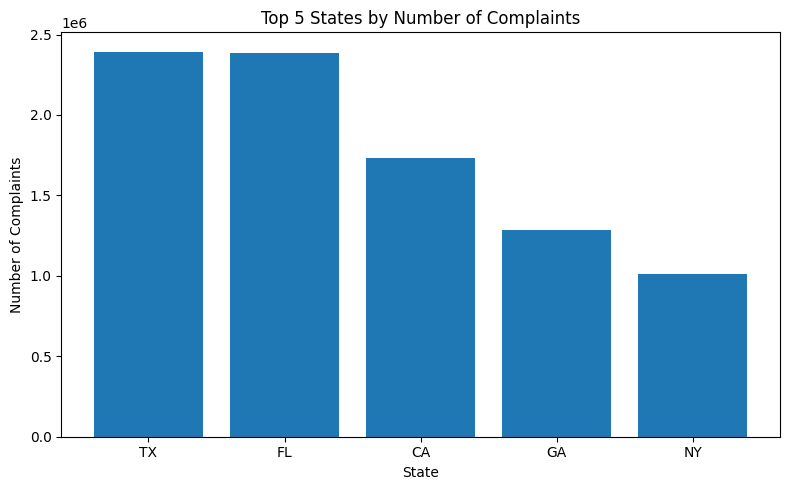

In [3]:
# ChatGPT generated code
import csv # Importing csv file for reading csv dataset
import pandas as pd # Importing pandas as pd for data processing
import matplotlib.pyplot as plt # Importing matplotlib for plotting bar chart
from collections import Counter # Importing counter class to assist finding counter of commonly found elements

file_path = "/anvil/projects/tdm/data/consumer_complaints/complaints.csv" # Defining the file path so program knows where to access file

with open(file_path, "r", encoding="utf-8", newline="") as f: # Opening the file
    reader = csv.reader(f) # Initializing reader object using csv.reader function
    header = next(reader) # Defining first row as the header

print("Variables in the dataset:")
print(header) # Outputting the column header/labels
state_index = header.index("State") # Finds index of state column
zip_index = header.index("ZIP code") # Finds index of ZIP code column

state_counts = Counter() # Creates counter object for number of state
zip_counts = Counter() # Creates counter object for number of zip code


with open(file_path, "r", encoding="utf-8", newline="") as f: # Reading the file
    reader = csv.reader(f) # Initialize reader object
    next(reader) # skips the first row 
    
    for row in reader: # Loop through all the rows
        # From my knowledge, this essentially creates a dictionary and a counter for all the zip codes and states
        if len(row) > state_index:
            state = row[state_index].strip()
            if state:
                state_counts[state] += 1 # Adds a counter to respective state if it matches state name     
        if len(row) > zip_index:
            zip_code = row[zip_index].strip()
            if zip_code:
                zip_counts[zip_code] += 1 # Adds a counter to respective zip code if it matches zip code number


top_5_states = state_counts.most_common(5) # Finds 5 most common states (by complaint number)
print("TOP 5 STATES BY NUMBER OF COMPLAINTS")
for state, count in top_5_states:
    print(f"{state}: {count:,}") # Prints each state and its respective complaint counter


top_5_zip_codes = zip_counts.most_common(5)
print("TOP 5 ZIP CODES BY NUMBER OF COMPLAINTS")
for zip_code, count in top_5_zip_codes:
    print(f"{zip_code}: {count:,}") # Prints each zip code and its respective complaint counter


states = [state for state, count in top_5_states] # Creates the independent variable for the x-axis (according to top 5 popular states)
complaints = [count for state, count in top_5_states] # Creates the dependent variable for the y-axis (according to their no. of complaints)

plt.figure(figsize=(8, 5)) # Creates a window in matplotlib that is 8 inches wide and 5 inches tall 
plt.bar(states, complaints) # Creates a bar chart with state as x-axis and complaints as y-axis
plt.title("Top 5 States by Number of Complaints") # Labeling the title
plt.xlabel("State") # Labeling the x-axis
plt.ylabel("Number of Complaints") # Labeling the y-axis
plt.tight_layout() # Fit everything neatly within specified frame
plt.show() # Displays the chart

Total records processed: 17,433,612

Top 5 states by complaint count:
  TX: 2,393,837
  FL: 2,386,173
  CA: 1,731,916
  GA: 1,285,440
  NY: 1,011,812

Top 5 zip codes (nationwide) by complaint count:
  XXXXX: 138,974
  30349: 33,171
  33025: 28,635
  77449: 28,295
  33311: 26,671


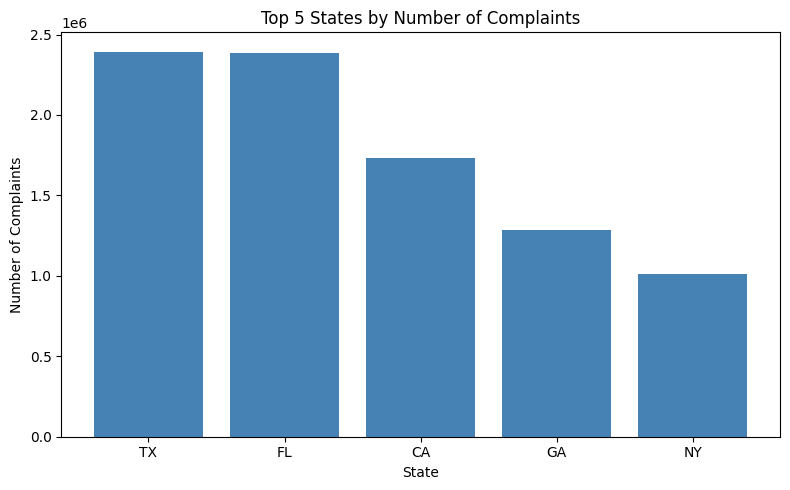

In [4]:
# Claude generated code

import csv
import sys
from collections import Counter
import matplotlib.pyplot as plt
# I am going to skip some commenting because a lot of this is repeated stuff, but this is importing for functionality of csv reading,
# creating counter object, plotting, and preventing reading error

FILE_PATH = "/anvil/projects/tdm/data/consumer_complaints/complaints.csv" # Defining the file path so program knows where to access file
csv.field_size_limit(sys.maxsize)

with open(FILE_PATH, mode="r", newline="", encoding="utf-8") as f: # Reading the file without opening
    reader = csv.reader(f) # Initializing reader object using csv.reader
    header = next(reader) # defining first row as the header

state_col = next(c for c in header if c.strip().lower() == "state") # Finds name of column for state
zip_col = next(c for c in header if "zip" in c.strip().lower()) # Finds name of column for zip code
state_idx = header.index(state_col) # Finds index of state column
zip_idx = header.index(zip_col) # Finds index of zip code column


state_counts = Counter() # Creates counter object for state
zip_counts = Counter() # Creates counter object for zip code

with open(FILE_PATH, mode="r", newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    next(reader)  # skip header
    for row in reader:
        state = row[state_idx].strip()
        zip_code = row[zip_idx].strip()
        if state:
            state_counts[state] += 1
        if zip_code:
            zip_counts[zip_code] += 1

# Finds highest complaint number sorted for each state and zip code
top5_states = state_counts.most_common(5)
top5_zips = zip_counts.most_common(5)

# Outputting the above info for top 5 most complaint by state
print("\nTop 5 states by complaint count:")
for state, count in top5_states:
    print(f"  {state}: {count:,}")

# Outputting the above info for top 5 most complaint by zip code
print("\nTop 5 zip codes (nationwide) by complaint count:")
for zip_code, count in top5_zips:
    print(f"  {zip_code}: {count:,}")

# A neat trick that combines the respective state and their counts together for easier processing and display
states, counts = zip(*top5_states)

# This is essentially the exact same as ChatGPT's code with the exception that color of bar is specified by claude
plt.figure(figsize=(8, 5))
plt.bar(states, counts, color="steelblue")
plt.xlabel("State")
plt.ylabel("Number of Complaints")
plt.title("Top 5 States by Number of Complaints")
plt.tight_layout()
plt.show()

Asked AI Models this:

- Return to the complaints from the full data set (not only from Indiana):
- Again, without reading the data frame into memory, how do I find the top 5 states, according to the number of complaints. Similarly, how do I find the top 5 zip codes (from the whole country, not just from Indiana), according to the number of complaints.
- It is OK if one of the zip codes shows "XXXXX".
- Finally, make a bar plot that shows the top 5 states, according to the number of complaints.

---

- The findings were actually very similar between the two, especially in the display of the graph, my hunch would be that there is quite a standardized method of how to write matplotlib bar chart code
- They also both utilize the counter library, making them both quite efficient
- One small difference would be that claude uses the zip function, reducing a bit of code and load
- Other than the sys implementation by Claude, they have quite similar approaches and hence there is not much to say except that generally, Claude is quite safe yet specific with its code -> it specifies bar chart color even though it's not necessarily needed so I guess this would be to standardize code to prevent version changes that may affect the display or so

## Question 4


2nd column: Product
12th column: Submitted via

COMPLAINTS BY PRODUCT
Counter({'Credit reporting or other personal consumer reports': 11900881, 'Credit reporting, credit repair services, or other personal consumer reports': 2163770, 'Debt collection': 1180909, 'Mortgage': 458565, 'Checking or savings account': 391036, 'Credit card': 338431, 'Credit card or prepaid card': 206356, 'Money transfer, virtual currency, or money service': 189178, 'Credit reporting': 140426, 'Student loan': 132646, 'Vehicle loan or lease': 101677, 'Bank account or service': 86198, 'Payday loan, title loan, personal loan, or advance loan': 36582, 'Consumer Loan': 31559, 'Payday loan, title loan, or personal loan': 30614, 'Prepaid card': 22801, 'Debt or credit management': 10027, 'Payday loan': 5528, 'Money transfers': 5354, 'Other financial service': 1056, 'Virtual currency': 18})


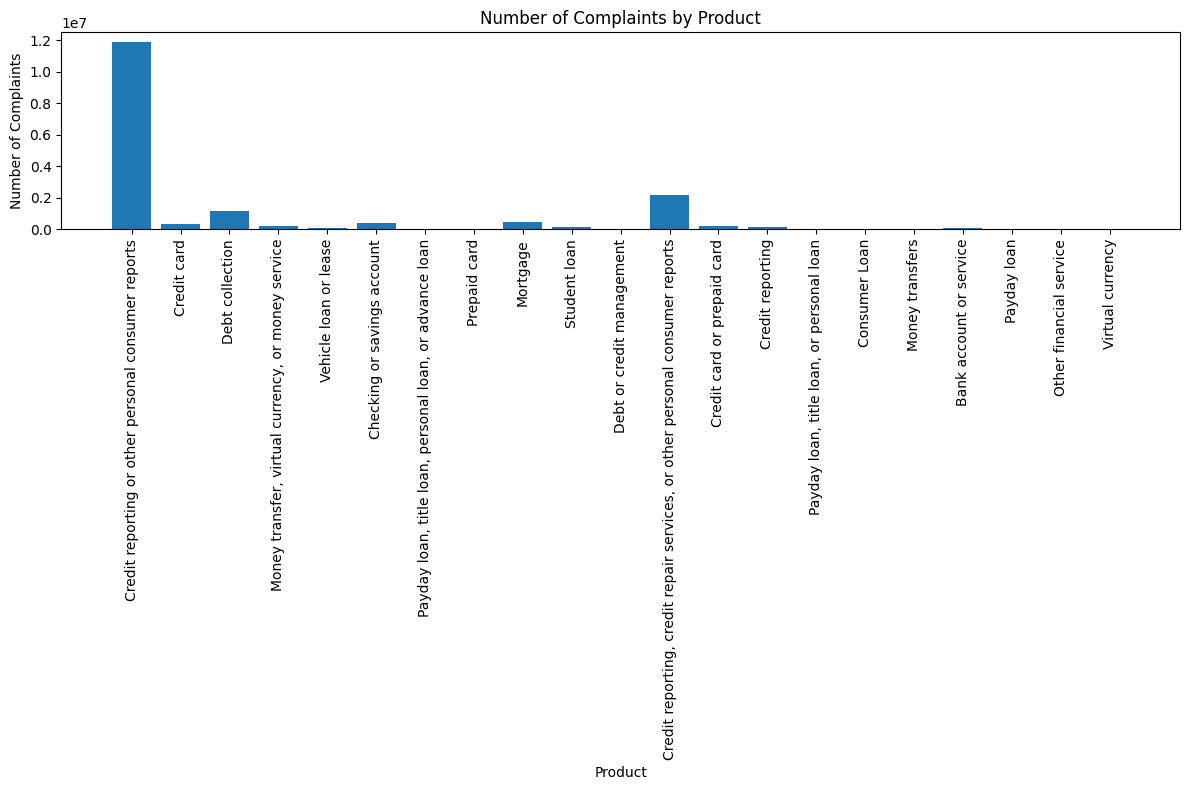


COMPLAINTS BY PRODUCT — EXCLUDING CREDIT REPORTING
Counter({'Credit reporting, credit repair services, or other personal consumer reports': 2163770, 'Debt collection': 1180909, 'Mortgage': 458565, 'Checking or savings account': 391036, 'Credit card': 338431, 'Credit card or prepaid card': 206356, 'Money transfer, virtual currency, or money service': 189178, 'Credit reporting': 140426, 'Student loan': 132646, 'Vehicle loan or lease': 101677, 'Bank account or service': 86198, 'Payday loan, title loan, personal loan, or advance loan': 36582, 'Consumer Loan': 31559, 'Payday loan, title loan, or personal loan': 30614, 'Prepaid card': 22801, 'Debt or credit management': 10027, 'Payday loan': 5528, 'Money transfers': 5354, 'Other financial service': 1056, 'Virtual currency': 18})


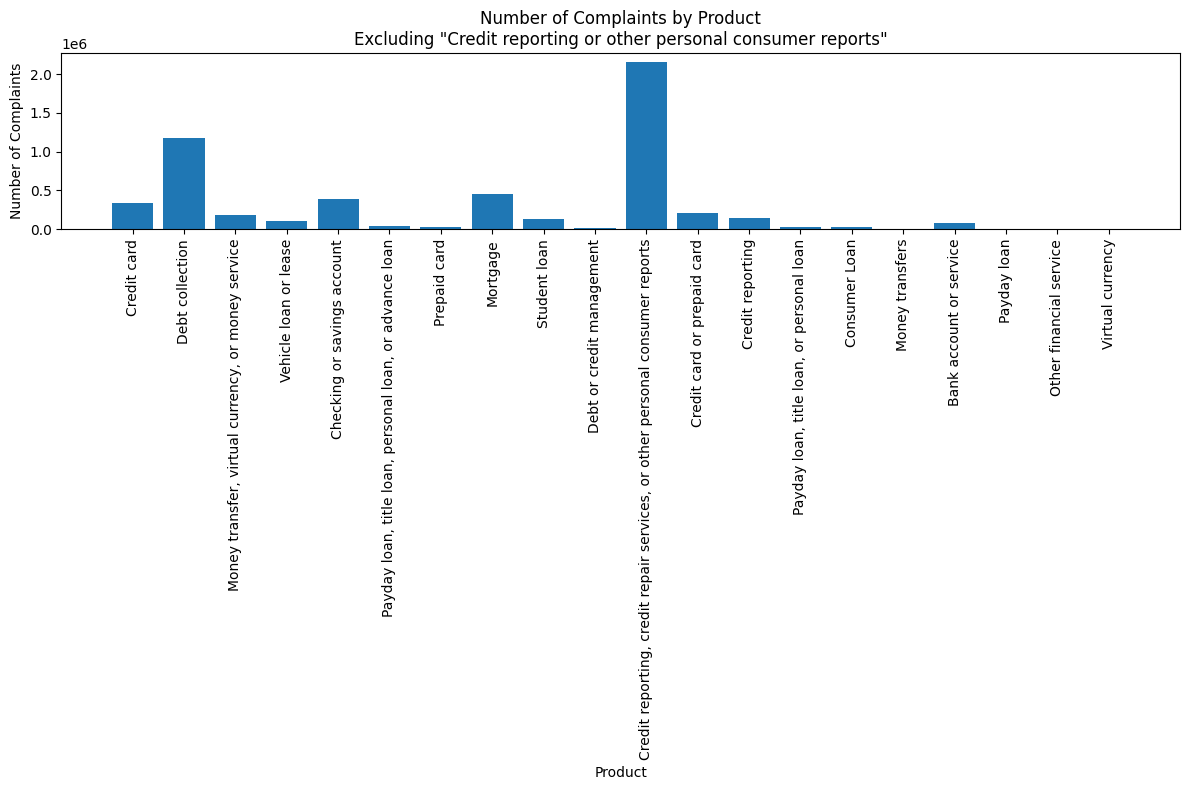


COMPLAINTS BY RESPONSE SUBMISSION METHOD
Counter({'Web': 16799062, 'Referral': 278070, 'Phone': 220129, 'Postal mail': 110284, 'Fax': 25644, 'Email': 423})


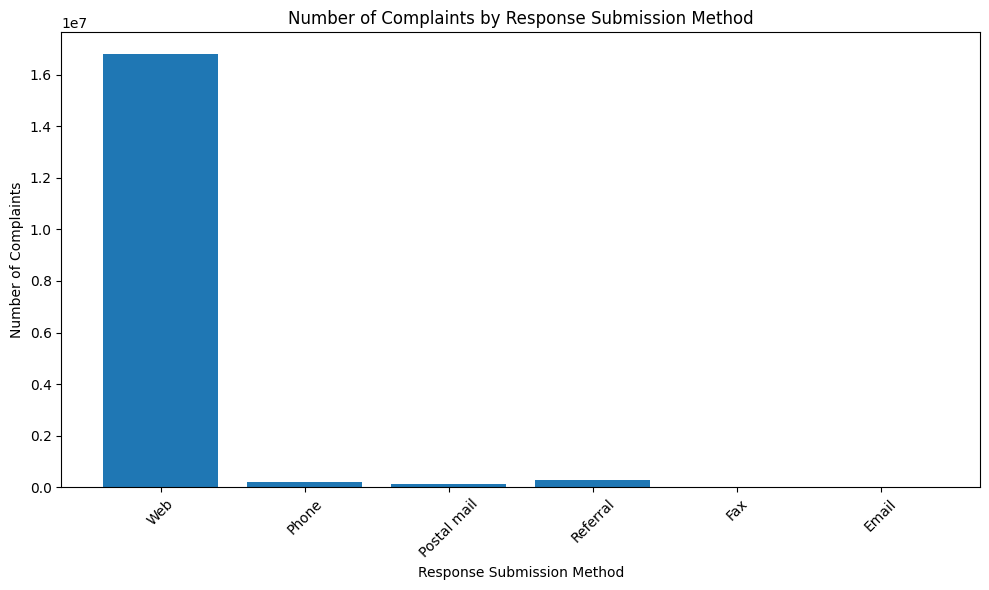


COMPLAINTS BY RESPONSE SUBMISSION METHOD — EXCLUDING WEB
Counter({'Referral': 278070, 'Phone': 220129, 'Postal mail': 110284, 'Fax': 25644, 'Email': 423})


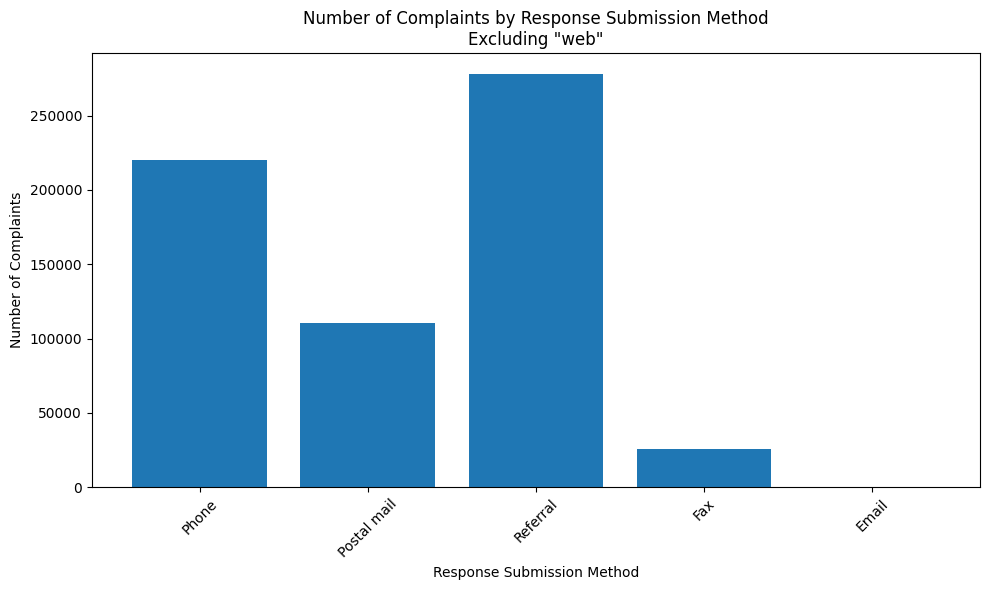

In [5]:
# ChatGPT generated code
import csv
import matplotlib.pyplot as plt
from collections import Counter
# Importing the libraries


file_path = "/anvil/projects/tdm/data/consumer_complaints/complaints.csv" # Defining the file path so program knows where to access file
PRODUCT_COLUMN = 1 # Initializing the 2nd column index as requested by the question
RESPONSE_COLUMN = 11 # Initializing the 11th column index as requested by the question
# Initializing values


with open(file_path, "r", encoding="utf-8", newline="") as f: # Same as all questions above, so I am skipping , 
    # but this is for whole dataset
    reader = csv.reader(f)
    header = next(reader)

# Printing 2nd and 12th column name so it shows user it is correct and hence making debuggging easier
print("\n2nd column:", header[PRODUCT_COLUMN])
print("12th column:", header[RESPONSE_COLUMN])

product_counts = Counter() # Initializing counter object according to number of complaints under a specific product type
response_counts = Counter() # Initializing counter object according to number of complaints under a specific response method


with open(file_path, "r", encoding="utf-8", newline="") as f:
    reader = csv.reader(f)
    next(reader) # Skip the header

    for row in reader:
        if len(row) > RESPONSE_COLUMN: # Make sure the row has at least 12 columns
            product = row[PRODUCT_COLUMN].strip()
            if product:
                product_counts[product] += 1 # Increments according to whatever the product type is, matched to its respective name

            response = row[RESPONSE_COLUMN].strip()
            if response:
                response_counts[response] += 1 # Increments according to whatever the response type is, matched to its respective name


print("COMPLAINTS BY PRODUCT")
print(product_counts) # Prints the dataset by product type

products = list(product_counts.keys()) # Lists all names of product types
product_values = list(product_counts.values()) # Lists all respective product values

# Same as before, data about the table
plt.figure(figsize=(12, 8))
plt.bar(products, product_values)
plt.title("Number of Complaints by Product")
plt.xlabel("Product")
plt.ylabel("Number of Complaints")

# Rotate labels because product names are long
plt.xticks(rotation=90)

# Same as before, some formatting and displaying
plt.tight_layout()
plt.show()


excluded_product = "Credit reporting or other personal consumer reports"

product_counts_no_credit_reporting = Counter({
    product: count
    for product, count in product_counts.items()
    if product != excluded_product
}) # Creates a new counter object that iterates through all object items and adds to the counter if it's not the excluded item



print("COMPLAINTS BY PRODUCT — EXCLUDING CREDIT REPORTING")
print(product_counts_no_credit_reporting) # Prints the dataset by product type minus credit reporting

products_no_credit_reporting = list(
    product_counts_no_credit_reporting.keys() # Lists all names of product types minus credit reporting
)

product_values_no_credit_reporting = list(
    product_counts_no_credit_reporting.values() # Lists all respective counts of product types minus credit reporting
)

# Same as before, plotting the bar chart and doing some minor adjustments like fitting to size and rotating to make more readable
plt.figure(figsize=(12, 8))
plt.bar(
    products_no_credit_reporting,
    product_values_no_credit_reporting
)
plt.title(
    'Number of Complaints by Product\n'
    'Excluding "Credit reporting or other personal consumer reports"'
)
plt.xlabel("Product")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()



print("COMPLAINTS BY RESPONSE SUBMISSION METHOD")
print(response_counts) # Output

responses = list(response_counts.keys())
response_values = list(response_counts.values())

# These are all the same, so once again, skipping, it's quite intuitive how it works
plt.figure(figsize=(10, 6))
plt.bar(responses, response_values)
plt.title("Number of Complaints by Response Submission Method")
plt.xlabel("Response Submission Method")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# Same as what is done for product type minus credit
response_counts_no_web = Counter({
    response: count
    for response, count in response_counts.items()
    if response.lower() != "web"
})


print("COMPLAINTS BY RESPONSE SUBMISSION METHOD — EXCLUDING WEB")
print(response_counts_no_web)

responses_no_web = list(response_counts_no_web.keys())
response_values_no_web = list(response_counts_no_web.values())

# These are all the same, so once again, skipping, it's quite intuitive how it works
plt.figure(figsize=(10, 6))
plt.bar(responses_no_web, response_values_no_web)
plt.title(
    'Number of Complaints by Response Submission Method\n'
    'Excluding "web"'
)
plt.xlabel("Response Submission Method")
plt.ylabel("Number of Complaints")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Columns in file:
  [0] Date received
  [1] Product
  [2] Sub-product
  [3] Issue
  [4] Sub-issue
  [5] Consumer complaint narrative
  [6] Company public response
  [7] Company
  [8] State
  [9] ZIP code
  [10] Tags
  [11] Submitted via
  [12] Date sent to company
  [13] Company response to consumer
  [14] Timely response?
  [15] Complaint ID

Using column [1] 'Product' as Product
Using column [11] 'Submitted via' as Submitted via


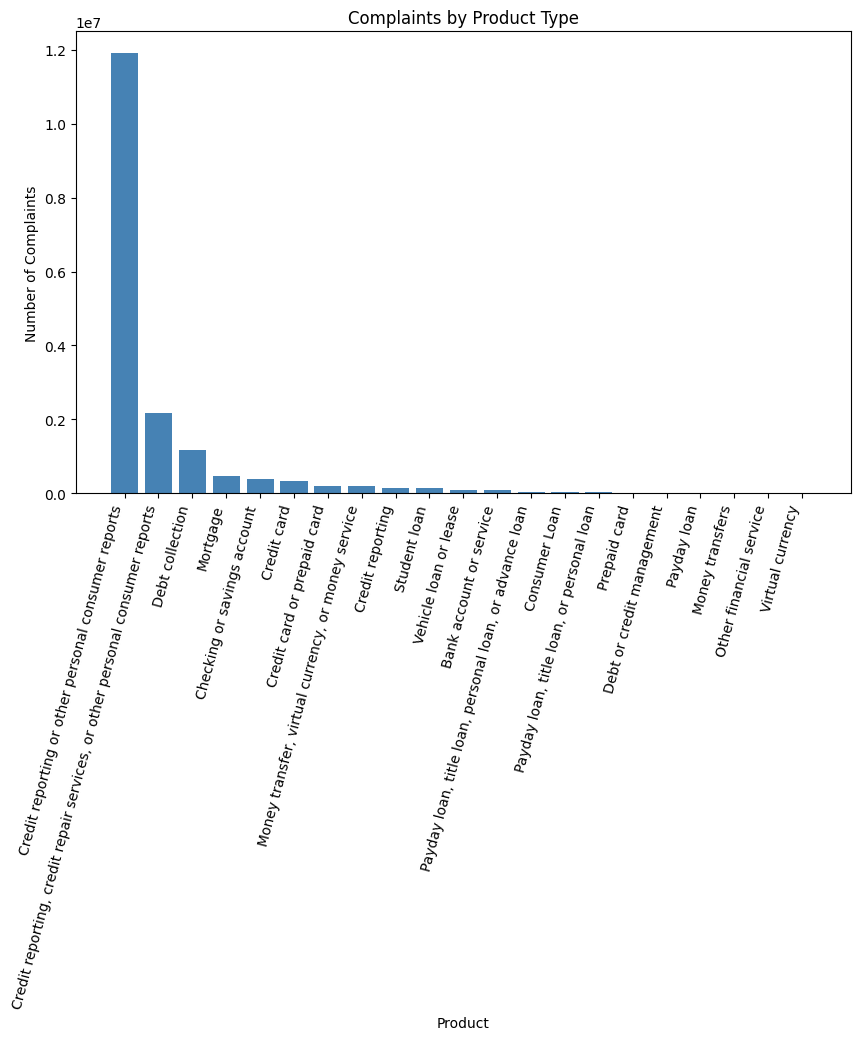

/tmp/ipykernel_938/3346979257.py:73: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


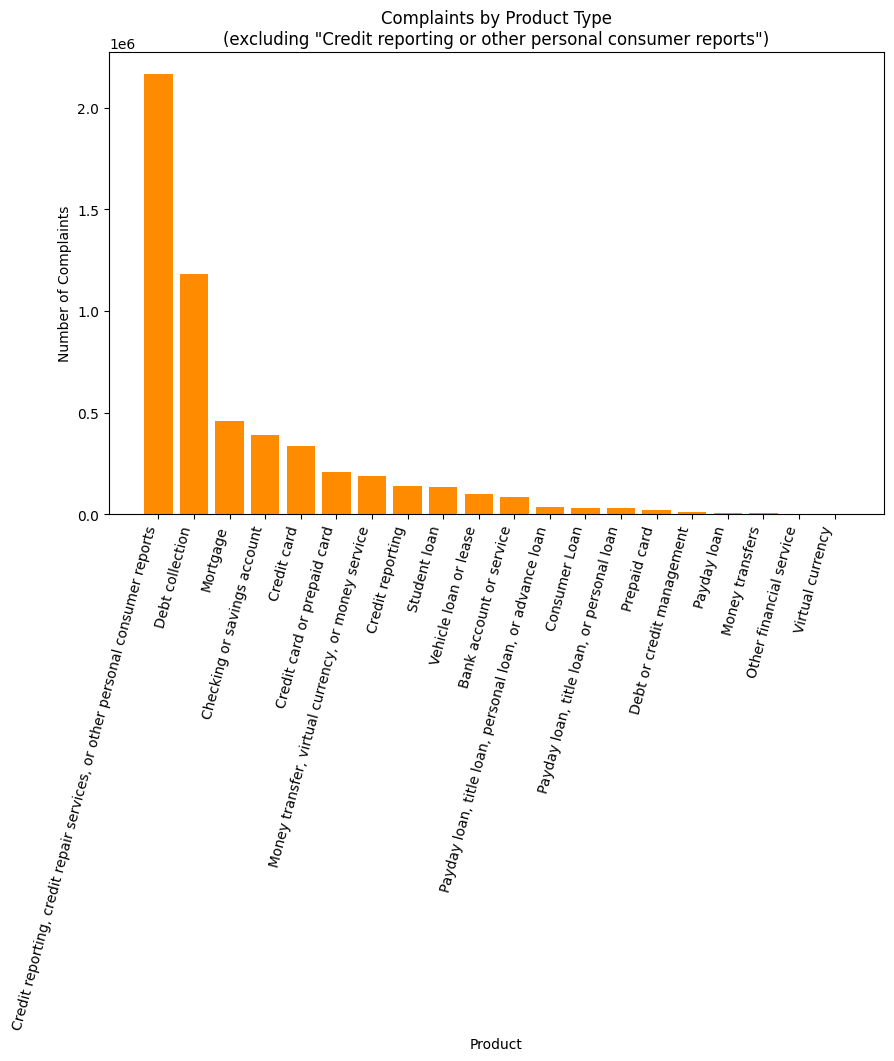

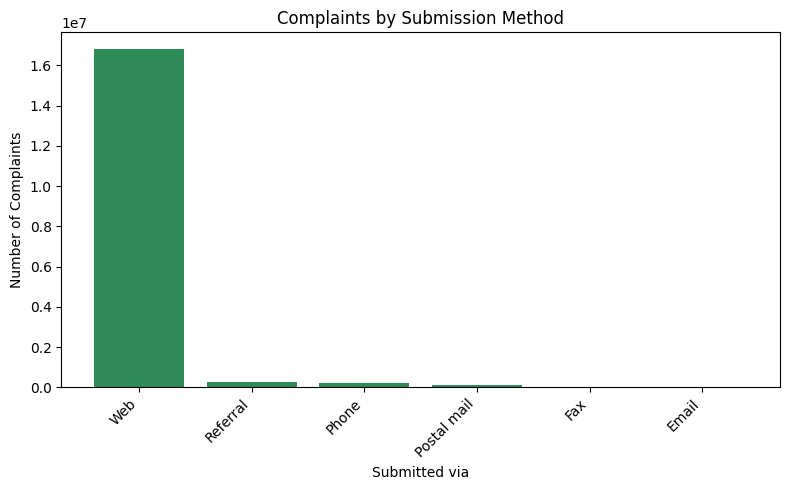

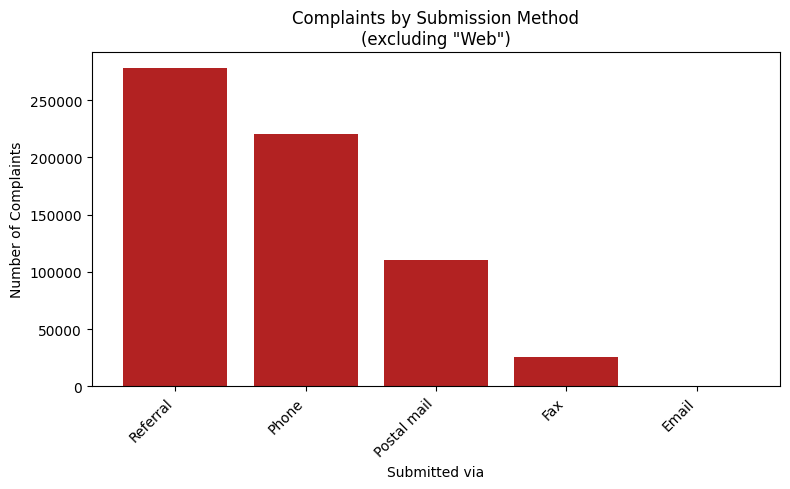

In [7]:
# Claude generated code
import csv
import sys
from collections import Counter
import matplotlib.pyplot as plt
# Importing the libraries

FILE_PATH = "/anvil/projects/tdm/data/consumer_complaints/complaints.csv" # Defining the file path so program knows where to access file
csv.field_size_limit(sys.maxsize)

# Same reading as before
with open(FILE_PATH, mode="r", newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    header = next(reader)

print("Columns in file:")
for i, col in enumerate(header):
    print(f"  [{i}] {col}")

product_idx = 1   # 2nd column
response_idx = 11  # 12th column

print(f"\nUsing column [{product_idx}] '{header[product_idx]}' as Product")
print(f"Using column [{response_idx}] '{header[response_idx]}' as Submitted via")
# Clarifying which index/column is used to help decoding

# Same counter initializing process
product_counts = Counter()
response_counts = Counter()


with open(FILE_PATH, mode="r", newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    next(reader)  # skip header
    for row in reader:
        product = row[product_idx].strip()
        response = row[response_idx].strip()
        if product:
            product_counts[product] += 1
        if response:
            response_counts[response] += 1


# This is for sorting by products
products_sorted = product_counts.most_common() # It's a bit different from ChatGPT
labels, counts = zip(*products_sorted) # This is the similar approach seen before
plt.figure(figsize=(10, 6))
plt.bar(labels, counts, color="steelblue")
plt.xlabel("Product")
plt.ylabel("Number of Complaints")
plt.title("Complaints by Product Type")
plt.xticks(rotation=75, ha="right") # horizontal alignment is adjusted
plt.show()


# This is the same conept as ChatGPT, just different variables
excluded_product = "Credit reporting or other personal consumer reports"
product_counts_filtered = Counter(
    {k: v for k, v in product_counts.items() if k != excluded_product}
)

products_sorted_f = product_counts_filtered.most_common()
labels_f, counts_f = zip(*products_sorted_f)

# Displaying the figures sorted by product minus credit repoting 
plt.figure(figsize=(10, 6))
plt.bar(labels_f, counts_f, color="darkorange")
plt.xlabel("Product")
plt.ylabel("Number of Complaints")
plt.title(f'Complaints by Product Type\n(excluding "{excluded_product}")')
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()


responses_sorted = response_counts.most_common()
r_labels, r_counts = zip(*responses_sorted)

# Displaying the figures sorted by response method
plt.figure(figsize=(8, 5))
plt.bar(r_labels, r_counts, color="seagreen")
plt.xlabel("Submitted via")
plt.ylabel("Number of Complaints")
plt.title("Complaints by Submission Method")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

excluded_response = "Web"
response_counts_filtered = Counter(
    {k: v for k, v in response_counts.items() if k.strip().lower() != excluded_response.lower()}
)

r_sorted_f = response_counts_filtered.most_common()
r_labels_f, r_counts_f = zip(*r_sorted_f)
# Displaying the figures sorted by response method minus the web
plt.figure(figsize=(8, 5))
plt.bar(r_labels_f, r_counts_f, color="firebrick")
plt.xlabel("Submitted via")
plt.ylabel("Number of Complaints")
plt.title(f'Complaints by Submission Method\n(excluding "{excluded_response}")')
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Asked AI Models this:

Work in a similar way to your previous response and what I previously asked:

- From the 2nd column, make a bar plot that shows the number of complaints, according to the type of Product involved.
- Now make another bar plot from the second column, showing the number of complaints, according to the type of Product involved, but this time remove the lines with Product: "Credit reporting or other personal consumer reports"
- Now do a similar analysis on column 12, Make a bar plot of the responses in the 12th column, about how the number of complaints, according to how the response was submitted.
- Now make another bar plot of the responses in the 12th column, about how the number of complaints, according to how the response was submitted, but this time remove the "web" responses


---

- Again, not much to analyze here as the two Gen AI models give essentially the same response, including the way they plot and how they standardize their display. However, I will say the only thing of note is that Claude actually explicitly states it wants the most popular ones, and it also uses the zip function, making it slightly mnore specific and efficient.

## Question 5

In [ ]:
# ChatGPT Code 
import csv
import matplotlib.pyplot as plt
from collections import Counter

# ============================================================
# SETTINGS
# ============================================================

file_path = "complaints.csv"
expected_records = 17_433_612

# Python uses zero-based indexing:
# 8th column  -> index 7
# 11th column -> index 10
# 14th column -> index 13
# 15th column -> index 14

COMPANY_COLUMN = 7
TAGS_COLUMN = 10
RESPONSE_COLUMN = 13
TIMELY_COLUMN = 14


# ============================================================
# READ HEADER
# ============================================================

with open(file_path, "r", encoding="utf-8", newline="") as f:
    reader = csv.reader(f)

    header = next(reader)

print("=" * 60)
print("VARIABLES IN THE DATASET")
print("=" * 60)

for i, column_name in enumerate(header, start=1):
    print(f"{i}. {column_name}")

print("\nColumns being analyzed:")
print(f"8th column  = {header[COMPANY_COLUMN]}")
print(f"11th column = {header[TAGS_COLUMN]}")
print(f"14th column = {header[RESPONSE_COLUMN]}")
print(f"15th column = {header[TIMELY_COLUMN]}")


# ============================================================
# COUNT VALUES
# ============================================================

company_counts = Counter()
tag_counts = Counter()
response_counts = Counter()
timely_counts = Counter()

record_count = 0

with open(file_path, "r", encoding="utf-8", newline="") as f:
    reader = csv.reader(f)

    # Skip header
    next(reader)
    for row in reader:
        record_count += 1

        # Make sure the row contains at least 15 columns
        if len(row) >= 15:
            company = row[COMPANY_COLUMN].strip()
            if company:
                company_counts[company] += 1

            tags = row[TAGS_COLUMN].strip()

            # Ignore blank Tags
            if tags:
                tag_counts[tags] += 1
            response = row[RESPONSE_COLUMN].strip()

            if response:
                response_counts[response] += 1


        
            timely = row[TIMELY_COLUMN].strip()

            if timely:
                timely_counts[timely] += 1

top_5_companies = company_counts.most_common(5)

print("\n" + "=" * 60)
print("TOP 5 COMPANIES")
print("=" * 60)

for company, count in top_5_companies:
    print(f"{company}: {count:,}")


print("\n" + "=" * 60)
print("TAGS — ALL NON-BLANK VALUES")
print("=" * 60)

# Sort alphabetically for easier reading
for tag, count in sorted(tag_counts.items()):
    print(f"{tag}: {count:,}")


print("\n" + "=" * 60)
print("COMPANY RESPONSE TO CONSUMER")
print("=" * 60)

for response, count in response_counts.most_common():
    print(f"{response}: {count:,}")


responses = list(response_counts.keys())
response_values = list(response_counts.values())

plt.figure(figsize=(10, 6))

plt.bar(responses, response_values)

plt.title("Number of Complaints by Company Response to Consumer")
plt.xlabel("Company Response to Consumer")
plt.ylabel("Number of Complaints")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()


print("\n" + "=" * 60)
print("TIMELY RESPONSE")
print("=" * 60)

print("Timely response counts:")

for value, count in timely_counts.items():
    print(f"{value}: {count:,}")

# Count total complaints for which Timely response has
# a non-blank value
timely_total = sum(timely_counts.values())

# Find the "Yes" count
yes_count = timely_counts.get("Yes", 0)

if timely_total > 0:
    timely_percentage = (yes_count / timely_total) * 100

    print(f"\nComplaints with a timely response: {yes_count:,}")
    print(f"Complaints with a recorded timely response: {timely_total:,}")
    print(f"Percentage with a timely response: {timely_percentage:.2f}%")
else:
    print("No non-blank timely-response values were found.")

VARIABLES IN THE DATASET
1. Date received
2. Product
3. Sub-product
4. Issue
5. Sub-issue
6. Consumer complaint narrative
7. Company public response
8. Company
9. State
10. ZIP code
11. Tags
12. Submitted via
13. Date sent to company
14. Company response to consumer
15. Timely response?
16. Complaint ID

Columns being analyzed:
8th column  = Company
11th column = Tags
14th column = Company response to consumer
15th column = Timely response?


In [ ]:
# Claude code

import csv
import sys
from collections import Counter
import matplotlib.pyplot as plt

FILE_PATH = "complaints.csv"  # update to your actual path
csv.field_size_limit(sys.maxsize)

# ---------------------------------------------------------
# Get header row and confirm column names/positions
# ---------------------------------------------------------
with open(FILE_PATH, mode="r", newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    header = next(reader)

print("Columns in file:")
for i, col in enumerate(header):
    print(f"  [{i}] {col}")

company_idx = 7    # 8th column
tags_idx = 10       # 11th column
comp_response_idx = 13  # 14th column
timely_idx = 14     # 15th column

print(f"\nUsing column [{company_idx}] '{header[company_idx]}' as Company")
print(f"Using column [{tags_idx}] '{header[tags_idx]}' as Tags")
print(f"Using column [{comp_response_idx}] '{header[comp_response_idx]}' as Company response to consumer")
print(f"Using column [{timely_idx}] '{header[timely_idx]}' as Timely response?")

# ---------------------------------------------------------
# Stream through the file once, tallying all four columns
# ---------------------------------------------------------
company_counts = Counter()
tag_counts = Counter()
comp_response_counts = Counter()
timely_counts = Counter()
total_rows = 0

with open(FILE_PATH, mode="r", newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    next(reader)  # skip header
    for row in reader:
        total_rows += 1

        company = row[company_idx].strip()
        if company:
            company_counts[company] += 1

        tag = row[tags_idx].strip()
        if tag:  # blanks intentionally excluded per question 2
            tag_counts[tag] += 1

        comp_response = row[comp_response_idx].strip()
        if comp_response:
            comp_response_counts[comp_response] += 1

        timely = row[timely_idx].strip()
        if timely:
            timely_counts[timely] += 1

print(f"\nTotal records processed: {total_rows:,}")

# ---------------------------------------------------------
# Q1: Top 5 companies (column 8)
# ---------------------------------------------------------
top5_companies = company_counts.most_common(5)
print("\nTop 5 companies by complaint count:")
for company, count in top5_companies:
    print(f"  {company}: {count:,}")

# ---------------------------------------------------------
# Q2: Tag values and counts (column 11), blanks excluded
# ---------------------------------------------------------
print("\nTag values and counts (blank excluded):")
for tag, count in tag_counts.most_common():
    print(f"  {tag}: {count:,}")

# ---------------------------------------------------------
# Q3: Bar plot of Company response to consumer (column 14)
# ---------------------------------------------------------
cr_sorted = comp_response_counts.most_common()
cr_labels, cr_counts = zip(*cr_sorted)

plt.figure(figsize=(10, 6))
plt.bar(cr_labels, cr_counts, color="mediumpurple")
plt.xlabel("Company Response to Consumer")
plt.ylabel("Number of Complaints")
plt.title("Complaints by Company Response to Consumer")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# Q4: Percentage of complaints with a timely response (column 15)
# ---------------------------------------------------------
print("\nTimely response value counts:")
for val, count in timely_counts.most_common():
    print(f"  {val}: {count:,}")

timely_yes = sum(count for val, count in timely_counts.items() if val.strip().lower() == "yes")
total_timely_col = sum(timely_counts.values())

pct_timely = (timely_yes / total_timely_col) * 100 if total_timely_col else 0
print(f"\nPercentage of complaints with a timely response: {pct_timely:.2f}%")
print(f"  ({timely_yes:,} 'Yes' out of {total_timely_col:,} non-blank responses)")

THIS IS INSTRUCTIONS, NOT EXPLANATION:

- In the 8th column, what are the top 5 companies that appear?
- The 11th column has Tags that are often blank, but when they are present, what are the values that appear there, and how many times does each value appear?
- Make a bar plot of the responses in the 14th column, about the number of complaints, according to the Company response to consumer.
- In the 15th column, what percentage of complaints had a timely response?

## Pledge

By submitting this work I hereby pledge that this is my own, personal work. I've acknowledged in the designated place at the top of this file all sources that I used to complete said work, including but not limited to: online resources, books, and electronic communications. I've noted all collaboration with fellow students and/or TA's. I did not copy or plagiarize another's work.

> As a Boilermaker pursuing academic excellence, I pledge to be honest and true in all that I do. Accountable together – We are Purdue.

https://www.purdue.edu/odos/osrr/honor-pledge/
